## Analysing snippets

In [16]:
import pandas as pd
from driver import clean_text, get_text_stats
import numpy as np
import re

logs_compiled = pd.read_csv("Data/logs_compiled.csv")
logs_compiled["timestamp"] = pd.to_datetime(logs_compiled["timestamp"])

logs_compiled["snippet"] = logs_compiled["snippet"].apply(lambda x: clean_text(x))
logs_compiled["snippet"] = logs_compiled["snippet"].apply(lambda x: re.sub(
    r'^(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Sept|Oct|Nov|Dec)\s+\d{1,2},\s+\d{4}\s*(?:\.\.\.)?\s*',
    '',
    x,
    flags=re.IGNORECASE
))
logs_compiled["snippet"] = logs_compiled["snippet"].apply(lambda x: x.strip())

text_stat_results = get_text_stats(logs_compiled, "snippet")

logs_compiled["snippet_content_len"] = text_stat_results["content_len"]
logs_compiled["snippet_mean_aoa"] = text_stat_results["mean_aoa"]
logs_compiled["snippet_mean_conc"] = text_stat_results["mean_conc"]
logs_compiled["snippet_gulpease_index"] = text_stat_results["gulpease_index"]
# logs_compiled["snippet_fres"] = text_stat_results["fres"]

  0%|          | 0/945 [00:00<?, ?it/s]

c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\hrishitachakra\AppData\Local\anaconda3\envs\pt_env\lib\site-packages\numpy\_core\_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [17]:
logs_compiled.to_csv("analysed_logs_compiled.csv", index=False, encoding='utf8')

## Analysing navigation

In [18]:
# nlp = spacy.load("it_core_news_sm")
logs_compiled = pd.read_csv("analysed_logs_compiled.csv")
navigation_quality = pd.read_csv("Data/navigation_quality.csv")
navigation_quality["last_relevant_timestamp"] = pd.to_datetime(navigation_quality["last_relevant_timestamp"])
navigation_quality["effective_nav"] = [int(nav_eff > 0.8) for nav_eff in navigation_quality["nav_eff"]]

In [19]:
logs_compiled.head()

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp,snippet_content_len,snippet_mean_aoa,snippet_mean_conc,snippet_gulpease_index
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://wwftravel.it/blog/viaggi/india-natura-...,"India naturalistica, 5 animali da non perdere ...","La fauna selvatica dell'India : tigri, leoni e...",1.0,1,2,2026-05-19 14:51:27.687,18,6.27,7.875,51.753623
1,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.terreincognitemagazine.it/natura-s...,"Natura selvaggia in India, tra tigri e leoni -...","O dei Giganti, vista la mole della fauna prese...",2.0,1,0,2026-05-19 14:51:27.688,24,7.53,5.025,68.615385
2,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.storicang.it/a/civilta-dellindo-i-...,"La civiltà dell'Indo, i misteri di un popolo d...","Sono note cinque metropoli, tra cui Harappa e ...",3.0,0,0,2026-05-19 14:51:27.689,18,NaN,NaN,64.864662
3,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.focusjunior.it/scuola/storia/chi-s...,"Chi sono gli Indiani d'America, i nativi ameri...","Chi sono, da dove vengono e quali tradizioni h...",4.0,0,0,2026-05-19 14:51:27.690,21,NaN,NaN,46.619048
4,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,https://www.focusjunior.it/comportamento/feste...,Festa della mamma: come si festeggia nel resto...,Il dolce tipico per celebrare questo giorno è ...,5.0,0,0,2026-05-19 14:51:27.691,26,4.12,7.200,62.791209


In [20]:
query_df = pd.read_csv("Data/query_df.csv")
query_df["timestamp"] = pd.to_datetime(query_df["timestamp"])

click_df = pd.read_csv("Data/clicked_results_df.csv")
click_df["timestamp"] = pd.to_datetime(click_df["timestamp"])

view_df = pd.read_csv("Data/viewed_results_df.csv")
view_df["timestamp"] = pd.to_datetime(view_df["timestamp"])

In [21]:
(query_df["timestamp"].max() - query_df["timestamp"].min()).total_seconds()

17030.947

In [22]:
query_df["timestamp"].mean()

Timestamp('2026-05-19 13:09:04.049101824')

In [23]:
first_click_time = []
avg_time_between_clicks = []
rank_lowest_click = []

for serp_id in navigation_quality["serp_id"]:
    query_temp_df = query_df[query_df["serp_id"] == serp_id].reset_index(drop=True)
    click_temp_df = click_df[click_df["serp_id"] == serp_id].reset_index(drop=True)

    first_click_time.append((click_temp_df["timestamp"].min() - query_temp_df["timestamp"].min()).total_seconds())
    rank_lowest_click.append(click_temp_df["rank"].max())

    time_between_consecutive_clicks = []
    if len(click_temp_df) <= 1:
        avg_time_between_clicks.append(0)
    else:
        click_temp_df = click_df[click_df["serp_id"] == "serp1"].reset_index(drop=True)

        for i, clicks in click_temp_df[1:].iterrows():
            time_between_consecutive_clicks.append((click_temp_df.iloc[i]["timestamp"]- click_temp_df.iloc[i-1]["timestamp"]).total_seconds())
        avg_time_between_clicks.append(np.mean(time_between_consecutive_clicks))


navigation_quality["first_click_time"] = first_click_time
navigation_quality["avg_time_between_clicks"] = avg_time_between_clicks
navigation_quality["rank_lowest_click"] = rank_lowest_click

navigation_quality.to_csv("Data/navigation_quality.csv", index=False, encoding="utf8")

In [24]:
navigation_quality.head()

,uid,topic_number,qid,query,serp_id,total_clicks,repetitions,tail,last_relevant_timestamp,nav_eff,effective_nav,first_click_time,avg_time_between_clicks,rank_lowest_click
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,2,1,0,2026-05-19 14:53:19.408,0.5,0,16.861,95.964,1
1,1,g3t2,q2,Quale è il nome del simbolo al centro della ba...,serp2,1,0,0,2026-05-19 15:02:48.776,1.0,1,7.656,0.000,1
2,1,g3t1,q3,Fiume sacro degli indiani,serp3,1,0,0,2026-05-19 15:08:58.405,1.0,1,18.880,0.000,2
3,2,g3t3,q5,Quali sono i 5 animali tipici dall'India,serp5,1,0,0,2026-05-19 14:52:53.759,1.0,1,93.570,0.000,1
4,2,g3t2,q7,Qual è il nome del simbolo al centro della b...,serp7,1,0,0,2026-05-19 15:09:25.575,1.0,1,19.258,0.000,3


<Axes: >

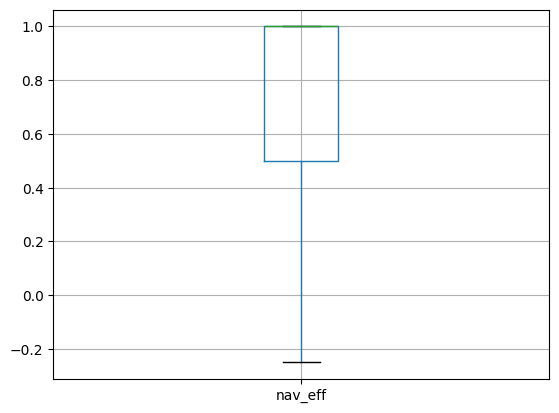

In [32]:
navigation_quality.boxplot(column="nav_eff")

In [38]:
len(navigation_quality.loc[navigation_quality["nav_eff"]>=0.8]), len(navigation_quality)

(33, 59)

In [34]:
clicks = pd.read_csv("Data/clicked_results_df.csv")
clicks.loc[(clicks["uid"]==11)&(clicks["serp_id"]=="serp64")]

,uid,topic_number,query,url,rank,timestamp,serp_id
70,11,g4t3,Quali sono i nomi di altre 3 galassie oltre la...,https://www.castfvg.it/galassie/gruppo_locale/...,3,2026-05-19 10:42:48.471,serp64
71,11,g4t3,Quali sono i nomi di altre 3 galassie oltre la...,https://www.focusjunior.it/scienza/spazio/stel...,1,2026-05-19 10:44:46.975,serp64
72,11,g4t3,Quali sono i nomi di altre 3 galassie oltre la...,https://www.focusjunior.it/scienza/spazio/stel...,1,2026-05-19 10:45:09.196,serp64
73,11,g4t3,Quali sono i nomi di altre 3 galassie oltre la...,https://www.focusjunior.it/scienza/spazio/stel...,1,2026-05-19 10:46:56.546,serp64


## Visualisation

In [25]:
from driver import get_boxplots, get_radar_plot
import pandas as pd

navigation_quality = pd.read_csv("Data/navigation_quality.csv")

categories = ["total_clicks", "repetitions", "tail", "first_click_time", "avg_time_between_clicks", "rank_lowest_click"]

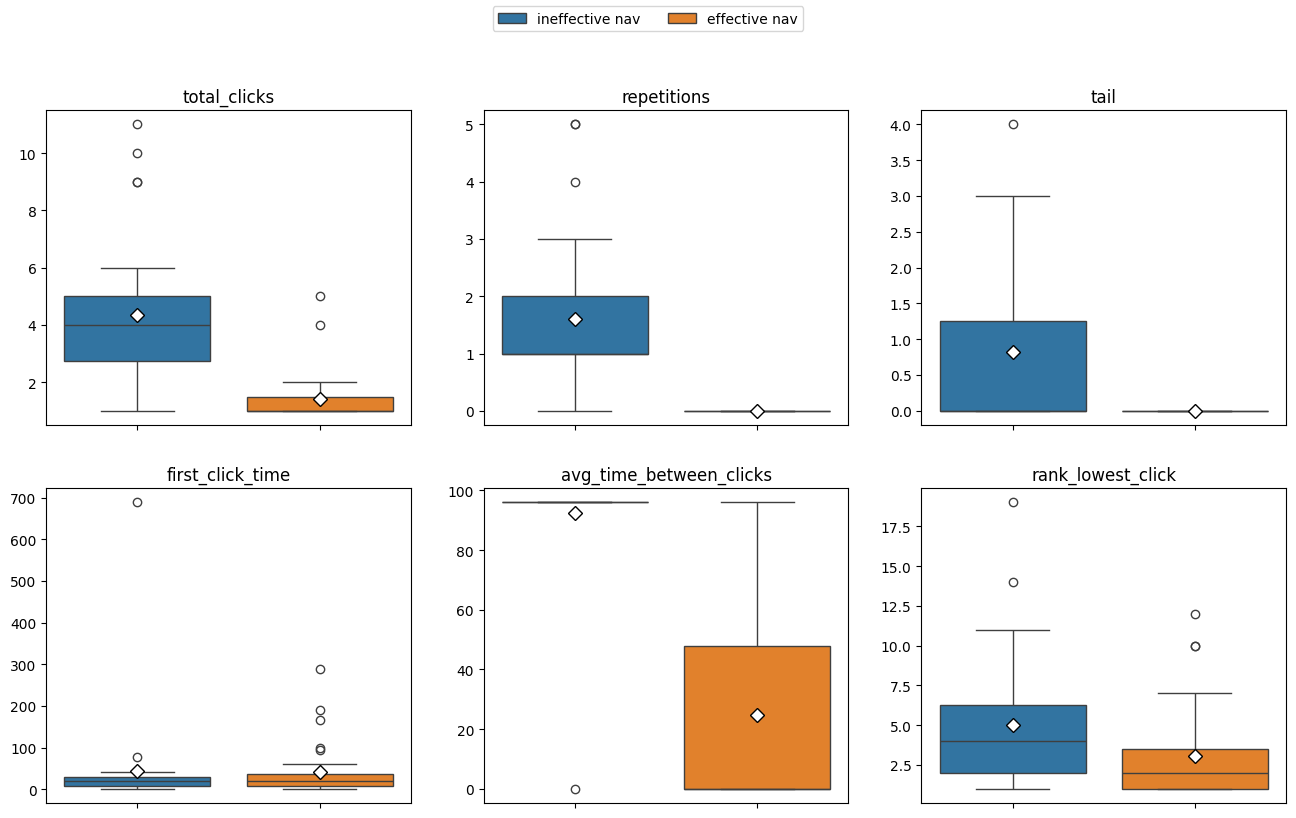

In [26]:
get_boxplots(df=navigation_quality, categories=categories, artefact="nav", group="effective_nav", n_cols=3, n_rows=2)

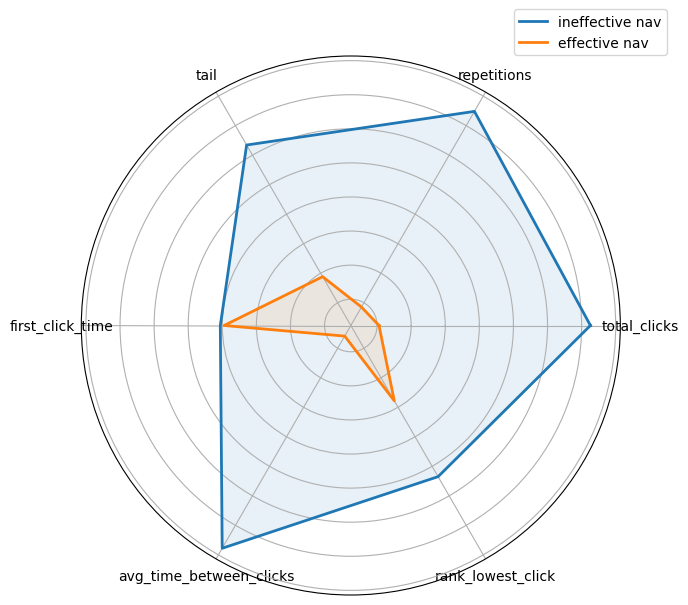

In [27]:
get_radar_plot(df=navigation_quality, categories=categories, artefact="nav", group="effective_nav", normalized=True)

In [28]:
first_logged_click, second_logged_click = click_df.iloc[0], click_df.iloc[1]
first_logged_click

uid                                                             1
topic_number                                                 g3t3
query               Quali sono i cinque animali tipici dell india
url             https://wwftravel.it/blog/viaggi/india-natura-...
rank                                                            1
timestamp                              2026-05-19 14:51:43.444000
serp_id                                                     serp1
Name: 0, dtype: object

In [29]:
view_df.loc[(view_df["serp_id"]==first_logged_click["serp_id"]) & (view_df["url"]==first_logged_click["url"]) & (view_df["timestamp"]<first_logged_click["timestamp"])]

,uid,topic_number,query,url,rank,viewType,timestamp,serp_id
0,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,resultExposureStarted,2026-05-19 14:51:27.960,serp1
3,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,resultExposureEnded,2026-05-19 14:51:43.438,serp1


In [30]:
view_df.loc[(view_df["serp_id"]==second_logged_click["serp_id"]) & (view_df["url"]==second_logged_click["url"]) & (view_df["timestamp"]<second_logged_click["timestamp"])]

,uid,topic_number,query,url,rank,viewType,timestamp,serp_id
0,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,resultExposureStarted,2026-05-19 14:51:27.960,serp1
3,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,resultExposureEnded,2026-05-19 14:51:43.438,serp1
6,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,resultExposureStarted,2026-05-19 14:53:01.804,serp1
8,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,resultExposureEnded,2026-05-19 14:53:03.757,serp1
33,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,resultExposureStarted,2026-05-19 14:53:13.477,serp1
34,1,g3t3,Quali sono i cinque animali tipici dell india,https://wwftravel.it/blog/viaggi/india-natura-...,1,resultExposureEnded,2026-05-19 14:53:19.402,serp1
